# Detection et comptage automatique de pieces marocaines (OpenCV)

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

## 1. Chargement de l'image

Taille image: (698, 600, 3)


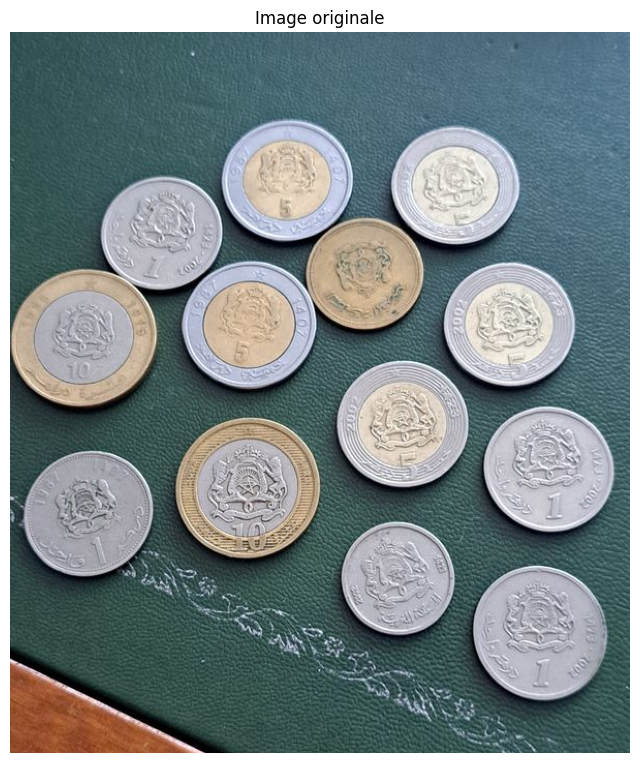

In [41]:
IMAGE_PATH = 'coins.png'  

img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Image introuvable: {IMAGE_PATH}")

print('Taille image:', img.shape)
plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Image originale')
plt.show()

## 2. Pretraitement (niveaux de gris + flou)

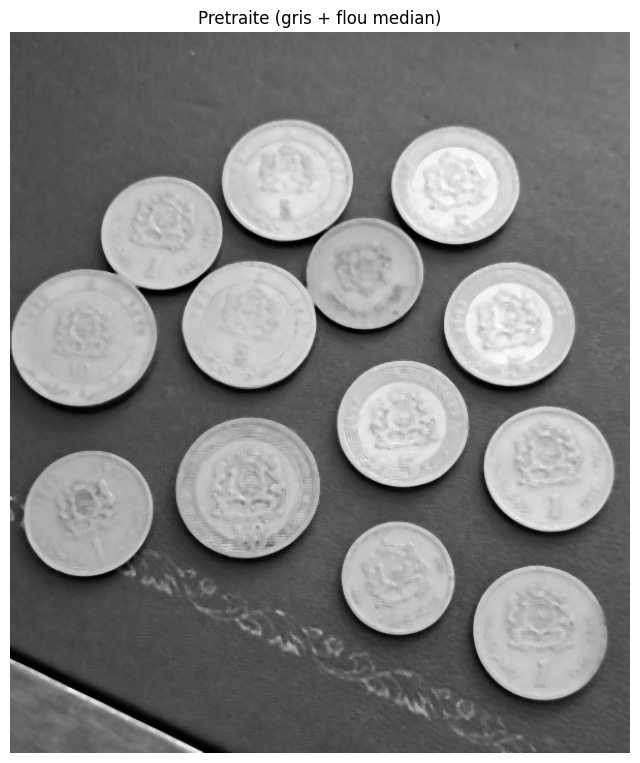

In [42]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_blur = cv2.medianBlur(gray, 5)

plt.figure(figsize=(8,10))
plt.imshow(gray_blur, cmap='gray')
plt.axis('off')
plt.title('Pretraite (gris + flou median)')
plt.show()

## 3. Detection des pieces (HoughCircles)



In [43]:
circles_raw = cv2.HoughCircles(
    gray_blur, cv2.HOUGH_GRADIENT, dp=1, minDist=60,
    param1=120, param2=40, minRadius=30, maxRadius=85)

if circles_raw is None:
    raise RuntimeError('Aucune piece detectee - ajuste les parametres ci-dessus')

circles = np.round(circles_raw[0, :]).astype(int)
print(f'{len(circles)} pieces detectees')

13 pieces detectees


## 4. Verification visuelle (cercles numerotes)

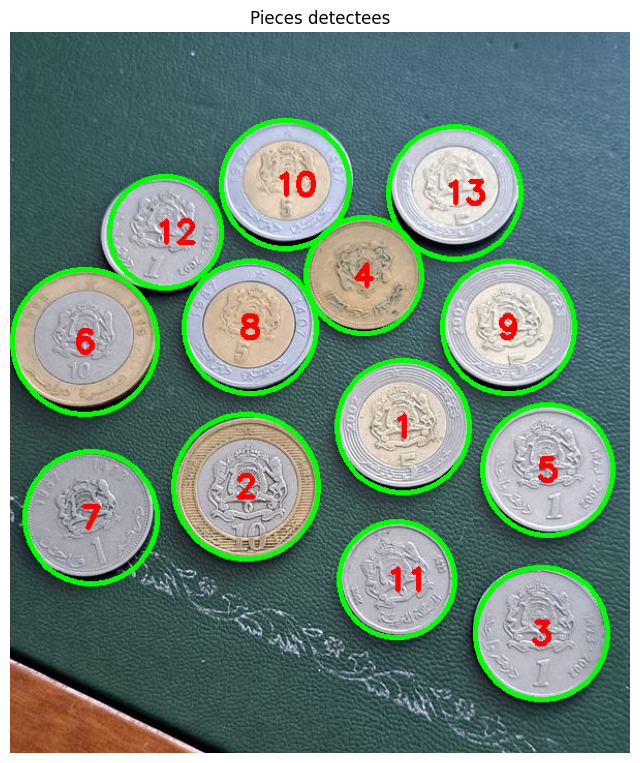

In [44]:
overlay = img.copy()
for i, (x, y, r) in enumerate(circles):
    cv2.circle(overlay, (x, y), r, (0, 255, 0), 3)
    cv2.putText(overlay, str(i+1), (x-10, y+10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,255), 3)

plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Pieces detectees')
plt.show()

## 5. Classification automatique (couleur HSV + taille)

In [45]:
def region_hue(hsv_img, x, y, r, inner_ratio, outer_ratio):
    mask = np.zeros(hsv_img.shape[:2], np.uint8)
    cv2.circle(mask, (x, y), int(r*outer_ratio), 255, -1)
    if inner_ratio > 0:
        cv2.circle(mask, (x, y), int(r*inner_ratio), 0, -1)
    h, s, v = cv2.mean(hsv_img, mask=mask)[:3]
    return h, s, v

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

features = []
for (x, y, r) in circles:
    c_hue, c_sat, _ = region_hue(hsv, x, y, r, 0, 0.4)      
    r_hue, r_sat, _ = region_hue(hsv, x, y, r, 0.6, 1.0)  
    features.append(dict(x=x, y=y, r=r, c_hue=c_hue, r_hue=r_hue))

In [46]:
GOLD_HUE_MAX = 45 

def classify_coin(feat):
    gold_center = feat['c_hue'] < GOLD_HUE_MAX
    gold_ring = feat['r_hue'] < GOLD_HUE_MAX
    if gold_center and not gold_ring:
        return 5.0
    if gold_center and gold_ring:
        return None   
    if not gold_center and gold_ring:
        return 10.0
    return None       


classification = {}
silver_mono = []
gold_mono = []

for i, feat in enumerate(features):
    val = classify_coin(feat)
    if val is None:
        if feat['c_hue'] < GOLD_HUE_MAX:
            gold_mono.append(i)     
        else:
            silver_mono.append(i)   
    else:
        classification[i] = val



DIAMETRES_MM = {
    10: 27.0,
    5: 25.0,
    1: 24.0,
    0.5: 21.0,
    0.20: 23.0,
    0.10: 20.0,
}

scale_samples = []
for i, val in classification.items():
    if val in DIAMETRES_MM:
        diametre_px = features[i]['r'] * 2
        scale_samples.append(diametre_px / DIAMETRES_MM[val])

px_per_mm = np.mean(scale_samples) if scale_samples else None
if px_per_mm:
    print(f"Echelle: {px_per_mm:.2f} px/mm\n")



if silver_mono and px_per_mm:
    rayon_1dh_attendu = (DIAMETRES_MM[1] * px_per_mm) / 2
    rayon_half_attendu = (DIAMETRES_MM[0.5] * px_per_mm) / 2
    seuil_silver = (rayon_1dh_attendu + rayon_half_attendu) / 2

    print(f"[Argente] Rayon attendu 1DH: {rayon_1dh_attendu:.1f}px | 1/2DH: {rayon_half_attendu:.1f}px | seuil: {seuil_silver:.1f}px")

    for i in silver_mono:
        classification[i] = 0.5 if features[i]['r'] < seuil_silver else 1.0



if gold_mono and px_per_mm:
    rayon_20c_attendu = (DIAMETRES_MM[0.20] * px_per_mm) / 2
    rayon_10c_attendu = (DIAMETRES_MM[0.10] * px_per_mm) / 2
    seuil_gold = (rayon_20c_attendu + rayon_10c_attendu) / 2

    print(f"[Dore] Rayon attendu 20c: {rayon_20c_attendu:.1f}px | 10c: {rayon_10c_attendu:.1f}px | seuil: {seuil_gold:.1f}px\n")

    for i in gold_mono:
        classification[i] = 0.10 if features[i]['r'] < seuil_gold else 0.20


# --- Etape 4 : affichage detaille ---
for i in sorted(classification):
    f = features[i]
    print(f"Piece {i+1}: r={f['r']}px, hue_centre={f['c_hue']:.0f}, hue_anneau={f['r_hue']:.0f} -> {classification[i]} DH")

Echelle: 5.12 px/mm

[Argente] Rayon attendu 1DH: 61.4px | 1/2DH: 53.7px | seuil: 57.6px
[Dore] Rayon attendu 20c: 58.8px | 10c: 51.2px | seuil: 55.0px

Piece 1: r=64px, hue_centre=17, hue_anneau=105 -> 5.0 DH
Piece 2: r=70px, hue_centre=136, hue_anneau=34 -> 10.0 DH
Piece 3: r=64px, hue_centre=120, hue_anneau=117 -> 1.0 DH
Piece 4: r=56px, hue_centre=18, hue_anneau=18 -> 0.2 DH
Piece 5: r=63px, hue_centre=122, hue_anneau=119 -> 1.0 DH
Piece 6: r=70px, hue_centre=121, hue_anneau=32 -> 10.0 DH
Piece 7: r=64px, hue_centre=117, hue_anneau=117 -> 1.0 DH
Piece 8: r=64px, hue_centre=16, hue_anneau=98 -> 5.0 DH
Piece 9: r=64px, hue_centre=23, hue_anneau=107 -> 5.0 DH
Piece 10: r=62px, hue_centre=17, hue_anneau=100 -> 5.0 DH
Piece 11: r=56px, hue_centre=123, hue_anneau=119 -> 0.5 DH
Piece 12: r=54px, hue_centre=118, hue_anneau=117 -> 0.5 DH
Piece 13: r=64px, hue_centre=20, hue_anneau=103 -> 5.0 DH


## 6. Resume et total

In [47]:
counts = Counter(classification.values())
total = sum(classification.values())

print('--- Resume ---')
for denom in sorted(counts, reverse=True):
    print(f'{denom} DH x {counts[denom]} = {denom*counts[denom]:.2f} DH')
print(f'\nTOTAL: {total:.2f} DH  ({len(classification)} pieces)')

--- Resume ---
10.0 DH x 2 = 20.00 DH
5.0 DH x 5 = 25.00 DH
1.0 DH x 3 = 3.00 DH
0.5 DH x 2 = 1.00 DH
0.2 DH x 1 = 0.20 DH

TOTAL: 49.20 DH  (13 pieces)


## 7. Image finale annotee

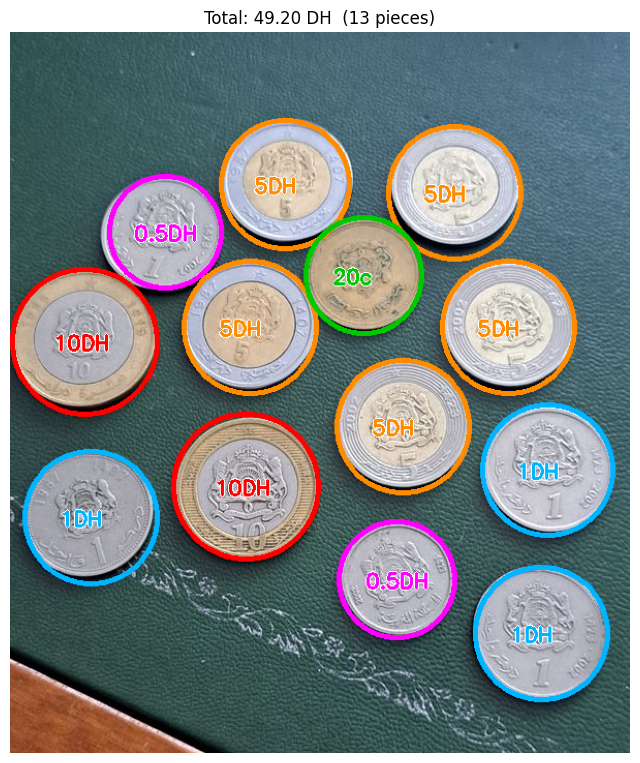

True

In [48]:
colors_bgr = {1.0: (255,180,0), 5.0: (0,140,255), 10.0: (0,0,255), 0.5: (255,0,255), 0.20: (0,200,0)}

final = img.copy()
for i, val in classification.items():
    x, y, r = circles[i]
    c = colors_bgr[val]
    label = f'{val:.0f}DH' if val >= 1 else (f'{int(val*100)}c' if val < 0.5 else '0.5DH')
    cv2.circle(final, (x, y), r, c, 4)
    cv2.putText(final, label, (x-30, y+8), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255,255,255), 4)
    cv2.putText(final, label, (x-30, y+8), cv2.FONT_HERSHEY_SIMPLEX, 0.65, c, 2)

plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f'Total: {total:.2f} DH  ({len(classification)} pieces)')
plt.show()

cv2.imwrite('resultat_final.png', final)